# Problem 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import statistics as st

# Part 1, number of claims

In [3]:
def sim_X(t):
    """
    Simulates a realization of X in the time interval t (days) with rate = 1.5
    """
    return np.random.poisson(t*1.5)

In [4]:
def CI(x):
    """
    Computes 95% CI with normal assumption
    """
    mean = np.mean(x)
    se = st.stdev(x)/np.sqrt(len(x)) # standard error
    z = 1.645 # 95th quantile of the standard normal distribution
    return (mean-z*se,mean+z*se)

In [ ]:
# 1000 realizations of X; there are 59 days between January 1st and March 1st
X = [sim_X(59) for i in range(1000)]

# Number of realizations greater than 100
X_gt_100 = [x > 100 for x in X]
CI_X = CI(X_gt_100)

print(f'Estimated probability that there are more than 100 claims by March 1st: {sum(X_gt_100)/len(X):.3f}')
print(f'95% CI: [{CI_X[0]:.3f},{CI_X[1]:.3f}]')

Estimated probability that there are more than 100 claims by March 1st: 0.100
95% CI: [0.084,0.116]


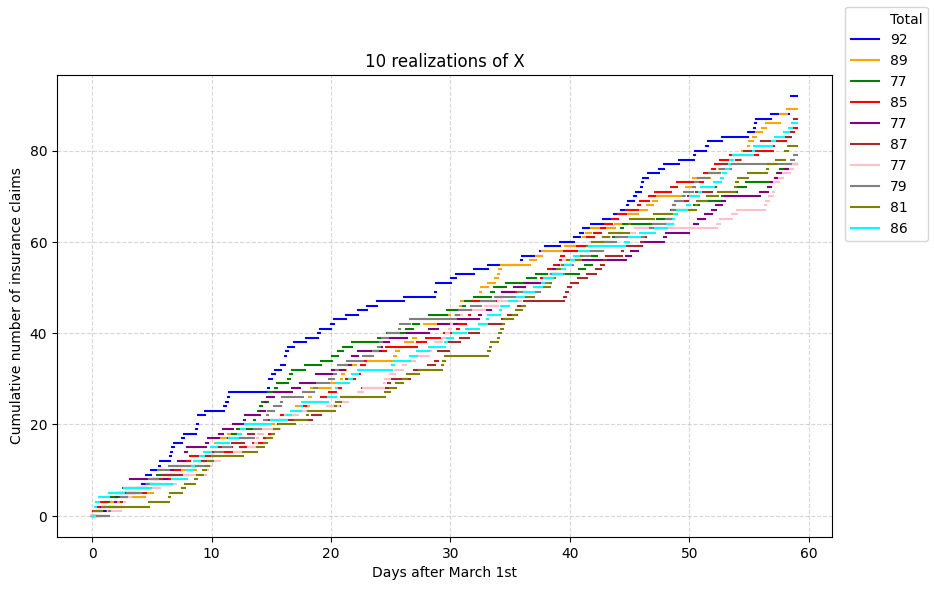

In [ ]:
# Plotting X(t) for t between 0 and t.
# Works by first generating x(t) and then choosing x(t) points
# in the interval 0 to t to be the occurance times.

ax, fig = plt.subplots(figsize=(10,6))
colors = ['blue','orange','green','red','purple','brown','pink','gray','olive','cyan']
plt.plot([np.nan],color='w',label='Total') # for legend

for j in range(10): # number of realizations
    t = 59
    x = sim_X(t)

    # Occurrence times of poisson process
    W = np.sort(np.random.uniform(0, t, x))

    # Plotting cumulative step function
    times = np.concatenate(([0], W, [t])) # making intervals
    counts = np.arange(len(times)) # cumulative count
    for i in range(len(counts)-1):
        plt.plot(np.linspace(times[i],times[i+1],2),[counts[i]]*2,color=colors[j])

    plt.plot([np.nan],color=colors[j],label=f'{x}') # for legend

plt.xlabel('Days after March 1st')
plt.ylabel('Cumulative number of insurance claims')
plt.title('10 realizations of X')
plt.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()

# Part 2, size of claims

In [ ]:
# Claim amount 
def sim_C():
    return np.random.exponential(0.1)

# Series of insurance claims
def sim_Z(t):
    return sum([sim_C() for x in range(sim_X(t))])

In [ ]:
# 1000 realizations
Z = [sim_Z(59) for i in range(1000)]

# Number of realizations greater than 8 mill kr
Z_gt_8 = [z > 8 for z in Z]
CI_X = CI(Z_gt_8)

print(f'Estimated probability that the total claim amount is larger than 8 mill kr. by March 1st: {sum(Z_gt_8)/len(Z):.3f}')
print(f'95% CI: [{CI_X[0]:.3f},{CI_X[1]:.3f}]')

Estimated probability that the total claim amount is larger than 8 mill kr. by March 1st: 0.719
95% CI: [0.696,0.742]


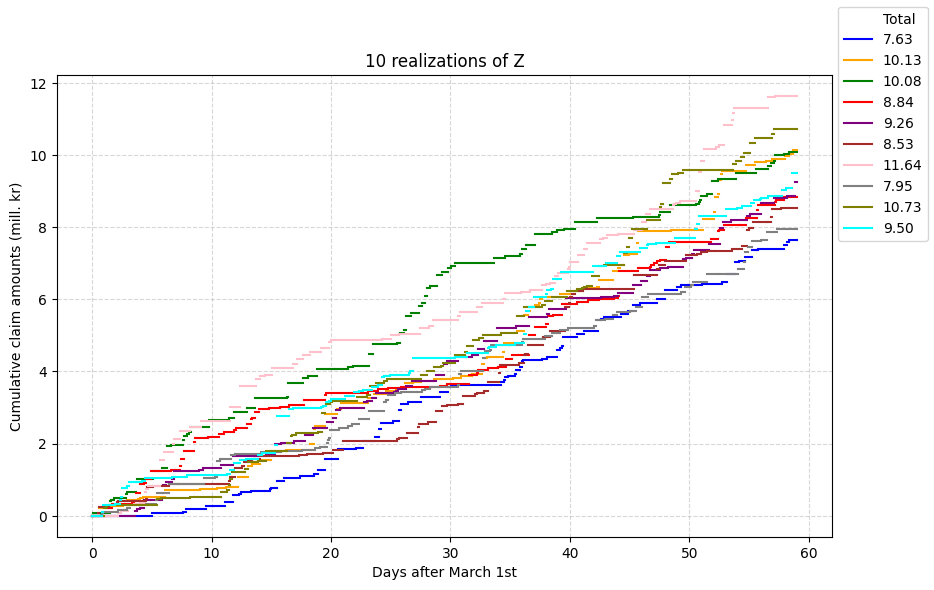

In [18]:
# Plotting Z(t) for t between 0 and t.
# Works the same way as plotting X(t), except using insurance amount instead.

ax, fig = plt.subplots(figsize=(10,6))
colors = ['blue','orange','green','red','purple','brown','pink','gray','olive','cyan']
plt.plot([np.nan],color='w',label='Total') # for legend

for j in range(10): # number of realizations
    t = 59
    x = sim_X(t)

    # Occurrence times of poisson process
    W = np.sort(np.random.uniform(0, t, x)) 

    # Claim amounts; cumulative variant of Z(t)
    C = np.cumsum(np.array([sim_C() for _ in range(x)]))

    # Creating cumulative step function
    times = np.concatenate(([0], W, [t]))
    amounts = np.concatenate(([0],C,[C[-1]]))
    for i in range(len(amounts)-1):
        plt.plot(np.linspace(times[i],times[i+1],2),[amounts[i]]*2,color=colors[j])

    plt.plot([np.nan],color=colors[j],label=f'{C[-1]:.2f}') # for legend

plt.xlabel('Days after March 1st')
plt.ylabel('Cumulative claim amounts (mill. kr)')
plt.title('10 realizations of Z')
ax.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()